# D3 — Evaluasi agen utuh di VALIDASI — Anggota D
**Versi data:** V3.1_A2_PROVISIONAL. **Split:** `random_split` = VALIDASI. UJI tidak dibaca.

Agen milik C dijalankan pada setiap berita VALIDASI dengan masukan mentah (judul + isi), sama seperti di aplikasi: preprocessing → `scope_guard` → `find_similar` → model + `decide`.

Yang diukur: coverage, galat pada berita yang diputuskan, kerugian harapan untuk C_FN 3/5/10, pembanding (model saja dengan ambang 0,5, ambang biaya, dan penolakan), kontribusi tiap lapisan, kinerja per sumber, kurva risk–coverage, kalibrasi (ECE seperti B3 dan ECE cross-fit), kesetaraan preprocessing, serta waktu respons.

Waktu jalan sekitar 2–3 menit di Colab gratis.

In [1]:
%pip -q install scikit-learn==1.6.1 pandas numpy scipy matplotlib joblib

## 1. Ambil repo
Isi `REPO_URL`, atau kosongkan lalu unggah zip repo yang sudah berisi paket D3.

In [2]:
import os, shutil, subprocess, sys, zipfile
from pathlib import Path

REPO_URL = ""   # contoh: "https://github.com/<akun>/Sistem-Deteksi-Berita-Hoaks-Berbahasa-Indonesia.git"
BRANCH = "main"

work = Path("/content/repo") if Path("/content").exists() else Path("repo")
TARGET = "d3_evaluasi_agen.py"

def extract(zpath, dest):
    """Ekstrak zip; pemisah '\\' dari zip buatan Windows diubah menjadi '/'."""
    with zipfile.ZipFile(zpath) as z:
        for info in z.infolist():
            name = info.filename.replace("\\", "/")
            if name.endswith("/") or "__MACOSX" in name:
                continue
            out = dest / name
            out.parent.mkdir(parents=True, exist_ok=True)
            with z.open(info) as src, open(out, "wb") as dst:
                shutil.copyfileobj(src, dst)

def find_repo():
    hits = [p for p in work.rglob(TARGET) if p.parent.name == "anggota_d" and p.parent.parent.name == "scripts"]
    return hits[0].parents[2] if hits else None

# Bersihkan sisa percobaan sebelumnya yang gagal
if work.exists() and find_repo() is None:
    shutil.rmtree(work)

if not work.exists():
    if REPO_URL:
        subprocess.run(["git", "clone", "--depth", "1", "-b", BRANCH, REPO_URL, str(work)], check=True)
    else:
        from google.colab import files
        up = files.upload()
        work.mkdir(parents=True)
        extract(next(iter(up)), work)

REPO_DIR = find_repo()
if REPO_DIR is None:
    print("Isi teratas zip/repo:", sorted(p.name for p in work.iterdir())[:20])
    for name in ["evaluate.py", "test_evaluate.py", TARGET, "D3_Evaluasi_Agen.ipynb", "B2_run_experiments.py"]:
        hits = list(work.rglob(name))
        print(f"  {name:32s}", "ADA: " + str(hits[0].relative_to(work)) if hits else "TIDAK ADA")
    raise FileNotFoundError(
        "scripts/anggota_d/d3_evaluasi_agen.py tidak ada. Kemungkinan besar isi PAKET_D3 "
        "belum diekstrak ke root repo sebelum repo di-zip / di-push. Ekstrak paket itu di root repo lalu ulangi.")
assert (REPO_DIR / "prototipe/anggota_c/src/evaluate.py").is_file(), "prototipe/anggota_c/src/evaluate.py belum ada di repo"
assert (REPO_DIR / "notebooks/anggota_b/scripts/B2_run_experiments.py").is_file(), "skrip B tidak ada di repo"
print("Repo:", REPO_DIR)

Saving Sistem-Deteksi-Berita-Hoaks-Berbahasa-Indonesia.zip to Sistem-Deteksi-Berita-Hoaks-Berbahasa-Indonesia.zip
Repo: /content/repo/Sistem-Deteksi-Berita-Hoaks-Berbahasa-Indonesia


## 2. Hubungkan Google Drive dan pilih dataset

In [3]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Bukan Google Colab: gunakan lokasi CSV di perangkat ini.")

DATASET_PATH = "/content/drive/MyDrive/Kelompok 5 - PSP/DATASET_V3_1_KANDIDAT_OPERASIONAL.csv"
assert Path(DATASET_PATH).is_file(), f"CSV tidak ditemukan. Ubah DATASET_PATH: {DATASET_PATH}"

Mounted at /content/drive


## 3. Jalankan evaluasi agen

In [4]:
OUTDIR = Path("/content/HASIL_D3") if Path("/content").exists() else Path("HASIL_D3")
r = subprocess.run([sys.executable, str(REPO_DIR / "scripts/anggota_d/d3_evaluasi_agen.py"),
                    "--dataset", DATASET_PATH, "--outdir", str(OUTDIR)],
                   capture_output=True, text=True)
print(r.stdout[-8000:])
if r.returncode != 0:
    print(r.stderr[-4000:])
    raise RuntimeError("Skrip gagal, lihat pesan di atas")

SHA-256 dataset: a790c0a6175455f385529f98a48dbd5ee8d939805494168ad698bd56343bb295
Sama dengan file A: True
VALIDASI: 2919 berita (832 HOAKS)
Status agen: {'preprocess': True, 'preprocess_version': 'V3.1', 'scope_guard_panjang': True, 'scope_guard_bahasa': True, 'find_similar': True, 'model': True, 'tau_similar': 0.9}
  500/2919 berita
  1000/2919 berita
  1500/2919 berita
  2000/2919 berita
  2500/2919 berita
Agen selesai dalam 64.3 detik

 c_fn             sistem  coverage  galat_diputuskan  fp  fn  ditolak  kerugian_harapan
  3.0   model_ambang_0.5  1.000000          0.005824   6  11        0          0.015416
  3.0 model_ambang_biaya  1.000000          0.006166   7  11        0          0.016101
  3.0     model_selektif  0.998287          0.004804   6   8        5          0.014046
  3.0               agen  0.989723          0.004846   6   8       30          0.022610
  5.0   model_ambang_0.5  1.000000          0.005824   6  11        0          0.022953
  5.0 model_ambang_biaya  1.

## 4. Hasil
- **Tabel sistem:** bandingkan `agen` dengan `model_selektif` dan `model_ambang_biaya` pada C_FN yang sama. Kerugian harapan yang lebih kecil lebih baik.
- **Tabel lapisan:** `scope_guard` dan `similar` menunjukkan berapa berita yang diambil alih lapisan reaktif, dan apakah model sebenarnya sudah benar untuk berita itu.
- **Per sumber:** semua hoaks berasal dari TurnBackHoax, jadi baca galat per sumber dengan hati-hati (lihat temuan *shortcut* sumber).

SHA-256 sama dengan file A: True | n = 2919
ECE seperti B3: 0.0039 | ECE cross-fit: 0.0042
Kesetaraan: {'porsi_teks_bersih_sama_persis': 0.9972593353888318, 'n_berita_dengan_p': 2919, 'selisih_p_maks': 0.0014437073537604886, 'keputusan_model_berbeda_cfn5': 0}
Latensi: {'p50_ms': 20.805817999644205, 'p95_ms': 30.419636100486965, 'mesin': 'Linux x86_64 | Python 3.13.18'}


,c_fn,sistem,coverage,galat_diputuskan,fp,fn,ditolak,kerugian_harapan,kerugian_harapan_ci95
0,3.0,model_ambang_0.5,1.000000,0.005824,6,11,0,0.015416,"[0.0086, 0.0236]"
1,3.0,model_ambang_biaya,1.000000,0.006166,7,11,0,0.016101,"[0.0092, 0.0243]"
2,3.0,model_selektif,0.998287,0.004804,6,8,5,0.014046,"[0.0075, 0.0212]"
3,3.0,agen,0.989723,0.004846,6,8,30,0.022610,"[0.0151, 0.0305]"
4,5.0,model_ambang_0.5,1.000000,0.005824,6,11,0,0.022953,"[0.0123, 0.0363]"
5,5.0,model_ambang_biaya,1.000000,0.005481,9,7,0,0.018157,"[0.0089, 0.0284]"
6,5.0,model_selektif,0.996574,0.003781,6,5,10,0.016101,"[0.0086, 0.0254]"
7,5.0,agen,0.988010,0.003814,6,5,35,0.024666,"[0.0161, 0.0346]"
8,10.0,model_ambang_0.5,1.000000,0.005824,6,11,0,0.041795,"[0.0212, 0.0671]"
9,10.0,model_ambang_biaya,1.000000,0.006852,15,5,0,0.027407,"[0.0130, 0.0445]"


,0,1,2
lapisan,scope_guard,similar,model
n,25,11,2883
porsi,0.008565,0.003768,0.987667
n_label_hoaks,25,11,796
n_alasan_bahasa,25.0,NaN,NaN
n_alasan_lainnya,0.0,NaN,NaN
model_akan_benar_tanpa_guard,25.0,NaN,NaN
n_diputuskan_hoaks,0,11,791
n_diputuskan_valid,0,0,2082
n_perlu_verifikasi,25,0,10


,source,n_hoaks,n,coverage,ditolak,galat_diputuskan,fp,fn,recall_hoaks_keseluruhan,kerugian_harapan,porsi_scope_guard,porsi_similar
0,CNN Indonesia,0,959,1.00000,0,0.001043,1,0,0.000000,0.002086,0.000000,0.000000
1,Kompas,0,486,0.99177,4,0.010373,5,0,0.000000,0.028807,0.000000,0.000000
2,Tempo,0,642,1.00000,0,0.000000,0,0,0.000000,0.000000,0.000000,0.000000
3,TurnBackHoax,832,832,0.96274,31,0.006242,0,5,0.956731,0.067308,0.030048,0.013221


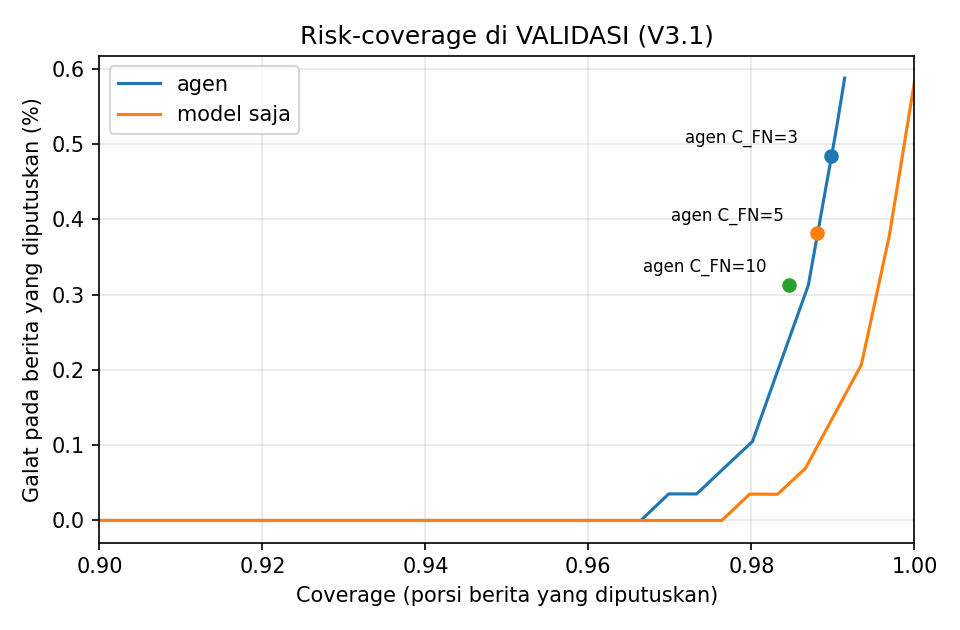

In [5]:
import json, pandas as pd
from IPython.display import Image, display
meta = json.loads((OUTDIR / "D3_METADATA.json").read_text())
print("SHA-256 sama dengan file A:", meta["sama_dengan_file_a"], "| n =", meta["n"])
print("ECE seperti B3:", round(meta["kalibrasi"]["ece_validasi_seperti_b3"], 4),
      "| ECE cross-fit:", round(meta["kalibrasi"]["ece_crossfit_2_lipatan"], 4))
print("Kesetaraan:", meta["kesetaraan_preprocessing"])
print("Latensi:", meta["latensi"])
cols = ["c_fn","sistem","coverage","galat_diputuskan","fp","fn","ditolak","kerugian_harapan","kerugian_harapan_ci95"]
display(pd.read_csv(OUTDIR / "D3_RINGKASAN_SISTEM.csv")[cols])
display(pd.read_csv(OUTDIR / "D3_LAPISAN.csv").T)
display(pd.read_csv(OUTDIR / "D3_PER_SUMBER.csv"))
display(Image(filename=str(OUTDIR / "D3_RISK_COVERAGE.png")))

## 5. Unduh hasil

In [6]:
zpath = OUTDIR.parent / "HASIL_D3_EVALUASI_AGEN.zip"
with zipfile.ZipFile(zpath, "w", zipfile.ZIP_DEFLATED) as z:
    for p in OUTDIR.rglob("*"):
        if p.is_file():
            z.write(p, p.relative_to(OUTDIR.parent))
print("Zip:", zpath)
try:
    from google.colab import files
    files.download(str(zpath))
except ImportError:
    pass

Zip: /content/HASIL_D3_EVALUASI_AGEN.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>